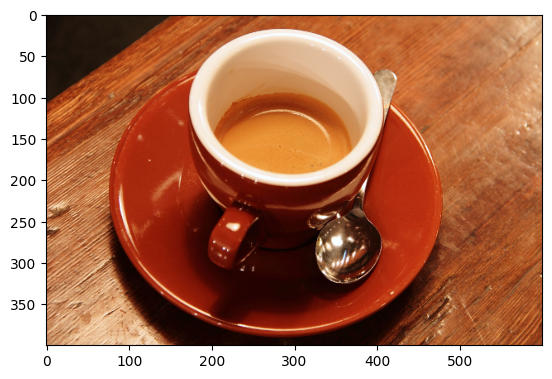

In [ ]:
plt.imshow(data.coffee())

In [4]:
import numpy as np
from scipy import stats
from skimage import color

def aplicar_filtro_espacial(img_gray, kernel_size, tipo='media'):
    pad_size = kernel_size // 2
    img_pad = np.pad(img_gray, pad_size, mode='edge')

    altura, largura = img_gray.shape
    img_out = np.zeros_like(img_gray)

    for i in range(altura):
        for j in range(largura):
            janela = img_pad[i:i+kernel_size, j:j+kernel_size]

            if tipo == 'media':
                img_out[i, j] = np.mean(janela)
            elif tipo == 'mediana':
                img_out[i, j] = np.median(janela)
            elif tipo == 'moda':
                valores, _ = stats.mode(janela, axis=None, keepdims=False)
                img_out[i, j] = valores
            elif tipo == 'maxima':
                img_out[i, j] = np.max(janela)

    return img_out

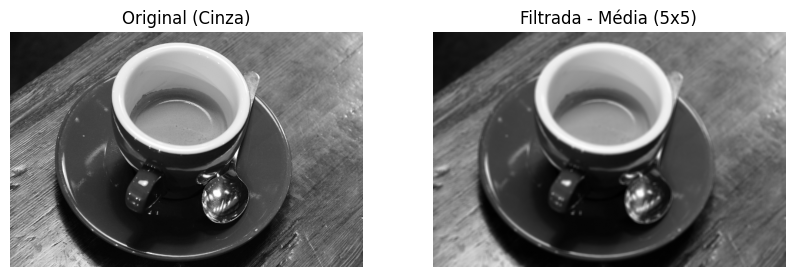

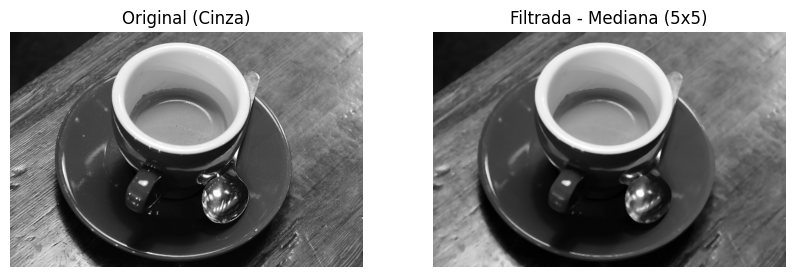

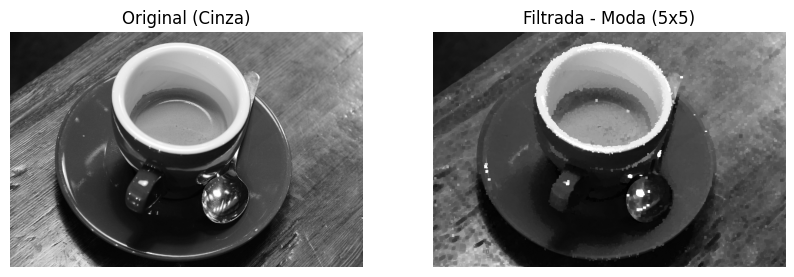

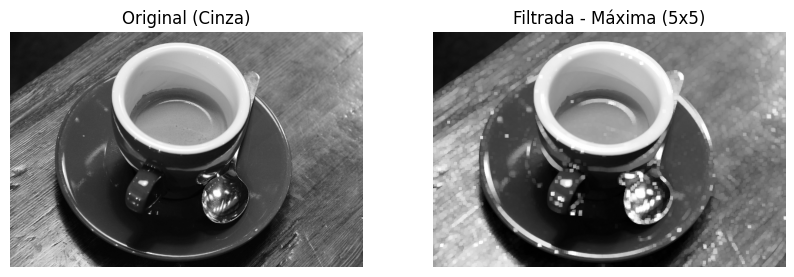

In [5]:
from skimage import data
import matplotlib.pyplot as plt

img_gray = color.rgb2gray(data.coffee())

img_media = aplicar_filtro_espacial(img_gray, 5, 'media')
img_mediana = aplicar_filtro_espacial(img_gray, 5, 'mediana')
img_moda = aplicar_filtro_espacial(img_gray, 5, 'moda')
img_maxima = aplicar_filtro_espacial(img_gray, 5, 'maxima')

def plot_comparacao(original, filtrada, nome_filtro):
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(original, cmap='gray')
    plt.title('Original (Cinza)')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(filtrada, cmap='gray')
    plt.title(f'Filtrada - {nome_filtro} (5x5)')
    plt.axis('off')

    plt.show()

plot_comparacao(img_gray, img_media, 'Média')
plot_comparacao(img_gray, img_mediana, 'Mediana')
plot_comparacao(img_gray, img_moda, 'Moda')
plot_comparacao(img_gray, img_maxima, 'Máxima')